# DSCI 552 Homework 4
**Name:** Yilin Chen  
**Github Username:** ychen501  
**USC ID:** 4414007229

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a)

In [2]:
DATA_DIR = Path("../data/AReM")
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES_COLS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
COLS = ["time"] + SERIES_COLS


def read_arem_csv(path):
    # "_extra" absorbs the trailing comma in some files
    df = pd.read_csv(path, comment="#", header=None, sep=r"[,\s]+", engine="python",
                     names=COLS + ["_extra"])
    return df[COLS]


def dataset_number(path):
    return int(re.search(r"\d+", path.stem).group())


instances = []
for activity in ACTIVITIES:
    files = sorted((DATA_DIR / activity).glob("dataset*.csv"), key=dataset_number)
    for path in files:
        instances.append({"activity": activity, "dataset": dataset_number(path),
                          "data": read_arem_csv(path)})

### (b)

In [3]:
def is_test(activity, dataset):
    if activity in ("bending1", "bending2"):
        return dataset <= 2
    return dataset <= 3


for inst in instances:
    inst["split"] = "test" if is_test(inst["activity"], inst["dataset"]) else "train"

### (c)
#### (c) i.

**c i Answer:**

Common time-domain features include minimum, maximum, range, mean, median, standard deviation, quartiles,skewness, kurtosis, root mean square  and autocorrelation.

#### (c) ii.

In [4]:
FEATURE_FUNCS = {
    "min":       np.min,
    "max":       np.max,
    "mean":      np.mean,
    "median":    np.median,
    "std":       lambda x: np.std(x, ddof=1),
    "1st_quart": lambda x: np.percentile(x, 25),
    "3rd_quart": lambda x: np.percentile(x, 75),
}


def extract_features(data, l=1):
    """Split each time series into l parts and extract features from every part."""
    features = {}
    for k, col in enumerate(SERIES_COLS, start=1):
        segments = np.array_split(data[col].to_numpy(), l)
        for j, seg in enumerate(segments, start=1):
            suffix = f"{k}" if l == 1 else f"{k}_part{j}"
            for name, func in FEATURE_FUNCS.items():
                features[name + suffix] = func(seg)
    return features


def build_feature_table(instances, l=1):
    rows = []
    for inst in instances:
        row = {"activity": inst["activity"], "dataset": inst["dataset"], "split": inst["split"]}
        row.update(extract_features(inst["data"], l))
        rows.append(row)
    table = pd.DataFrame(rows)
    table.index = pd.RangeIndex(1, len(table) + 1, name="Instance")
    return table

In [5]:
features = build_feature_table(instances, l=1)
feature_cols = [c for c in features.columns if c not in ("activity", "dataset", "split")]
features[feature_cols].round(2)

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.62,40.50,1.48,39.25,42.00,0.0,1.30,0.36,...,2.19,33.00,36.00,0.00,1.92,0.57,0.43,0.58,0.00,1.30
2,38.00,45.67,42.81,42.50,1.44,42.00,43.67,0.0,1.22,0.37,...,2.00,32.00,34.50,0.00,3.11,0.57,0.43,0.60,0.00,1.30
3,35.00,47.40,43.95,44.33,1.56,43.00,45.00,0.0,1.70,0.43,...,2.00,35.36,36.50,0.00,1.79,0.49,0.43,0.51,0.00,0.94
4,33.00,47.75,42.18,43.50,3.67,39.15,45.00,0.0,3.00,0.70,...,3.85,30.46,36.33,0.00,2.18,0.61,0.50,0.52,0.00,1.00
5,33.00,45.75,41.68,41.75,2.24,41.33,42.75,0.0,2.83,0.54,...,2.41,28.46,31.25,0.00,1.79,0.38,0.43,0.39,0.00,0.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.59,34.25,4.65,30.25,37.00,0.0,14.67,4.58,...,3.28,13.73,18.25,0.00,8.32,3.26,3.11,1.64,2.05,4.32
85,19.75,45.50,34.32,35.25,4.75,31.00,38.00,0.0,13.47,4.46,...,3.12,13.50,17.75,0.00,9.67,3.43,3.20,1.73,2.16,4.56
86,19.50,46.00,34.55,35.25,4.84,31.25,37.81,0.0,12.47,4.37,...,2.82,14.00,17.75,0.00,10.00,3.34,3.08,1.66,2.16,4.34


#### (c) iii.

In [6]:
X = features[feature_cols]
B = 1000
SEED = 42

point_std = X.std(ddof=1)

boot_stds = np.empty((B, X.shape[1]))
for b in range(B):
    sample = X.sample(frac=1, replace=True, random_state=SEED + b)
    boot_stds[b] = sample.std(ddof=1).to_numpy()

ci_table = pd.DataFrame({
    "Feature": feature_cols,
    "Std (point estimate)": point_std.to_numpy(),
    "90% CI lower (5th pct)": np.percentile(boot_stds, 5, axis=0),
    "90% CI upper (95th pct)": np.percentile(boot_stds, 95, axis=0),
})
ci_table.index = pd.RangeIndex(1, len(ci_table) + 1)
ci_table.round(3)

,Feature,Std (point estimate),90% CI lower (5th pct),90% CI upper (95th pct)
1,min1,9.570,8.287,10.760
2,max1,4.394,3.327,5.312
3,mean1,5.336,4.714,5.888
4,median1,5.440,4.797,6.001
5,std1,1.772,1.564,1.950
6,1st_quart1,6.154,5.564,6.670
7,3rd_quart1,5.139,4.332,5.853
8,min2,0.000,0.000,0.000
9,max2,5.063,4.626,5.393
10,mean2,1.574,1.400,1.713


#### (c) iv.

**c iv Answer:**

The three most important features are **mean, standard deviation and maximum**.
- **Mean:** the avg_rss signals depend on the distance between the sensors. Lying, sitting, standing and bending all put the sensors at different distances, so the mean level of each series is the most direct way to tell these activities apart. 
- **Standard deviation:** It measures how much the signal changes during the 120 seconds. In static activities, such as lying, sitting and standing, the body hardly moves, so the signals are stable. However, in walking and cycling, the body keeps moving, so the signals change a lot. So Standard deviation separates moving activities from static ones.
- **Maximum:** It represents short peaks from sudden movements, such as stepping. These peaks are short, so they barely affect the mean, but the maximum keeps them.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

In [7]:
META_COLS = ["activity", "dataset", "split"]
SEED = 42

tables = {}
for l in range(1, 21):
    tables[l] = build_feature_table(instances, l)


def get_data(l, split, multiclass=False):
    t = tables[l][tables[l]["split"] == split]
    X = t.drop(columns=META_COLS)
    if multiclass:
        y = t["activity"].to_numpy()
    else:
        y = t["activity"].isin(["bending1", "bending2"]).astype(int).to_numpy()   
        
    return X, y


skf = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)

### (a) Binary Classification Using Logistic Regression
#### (a) i.

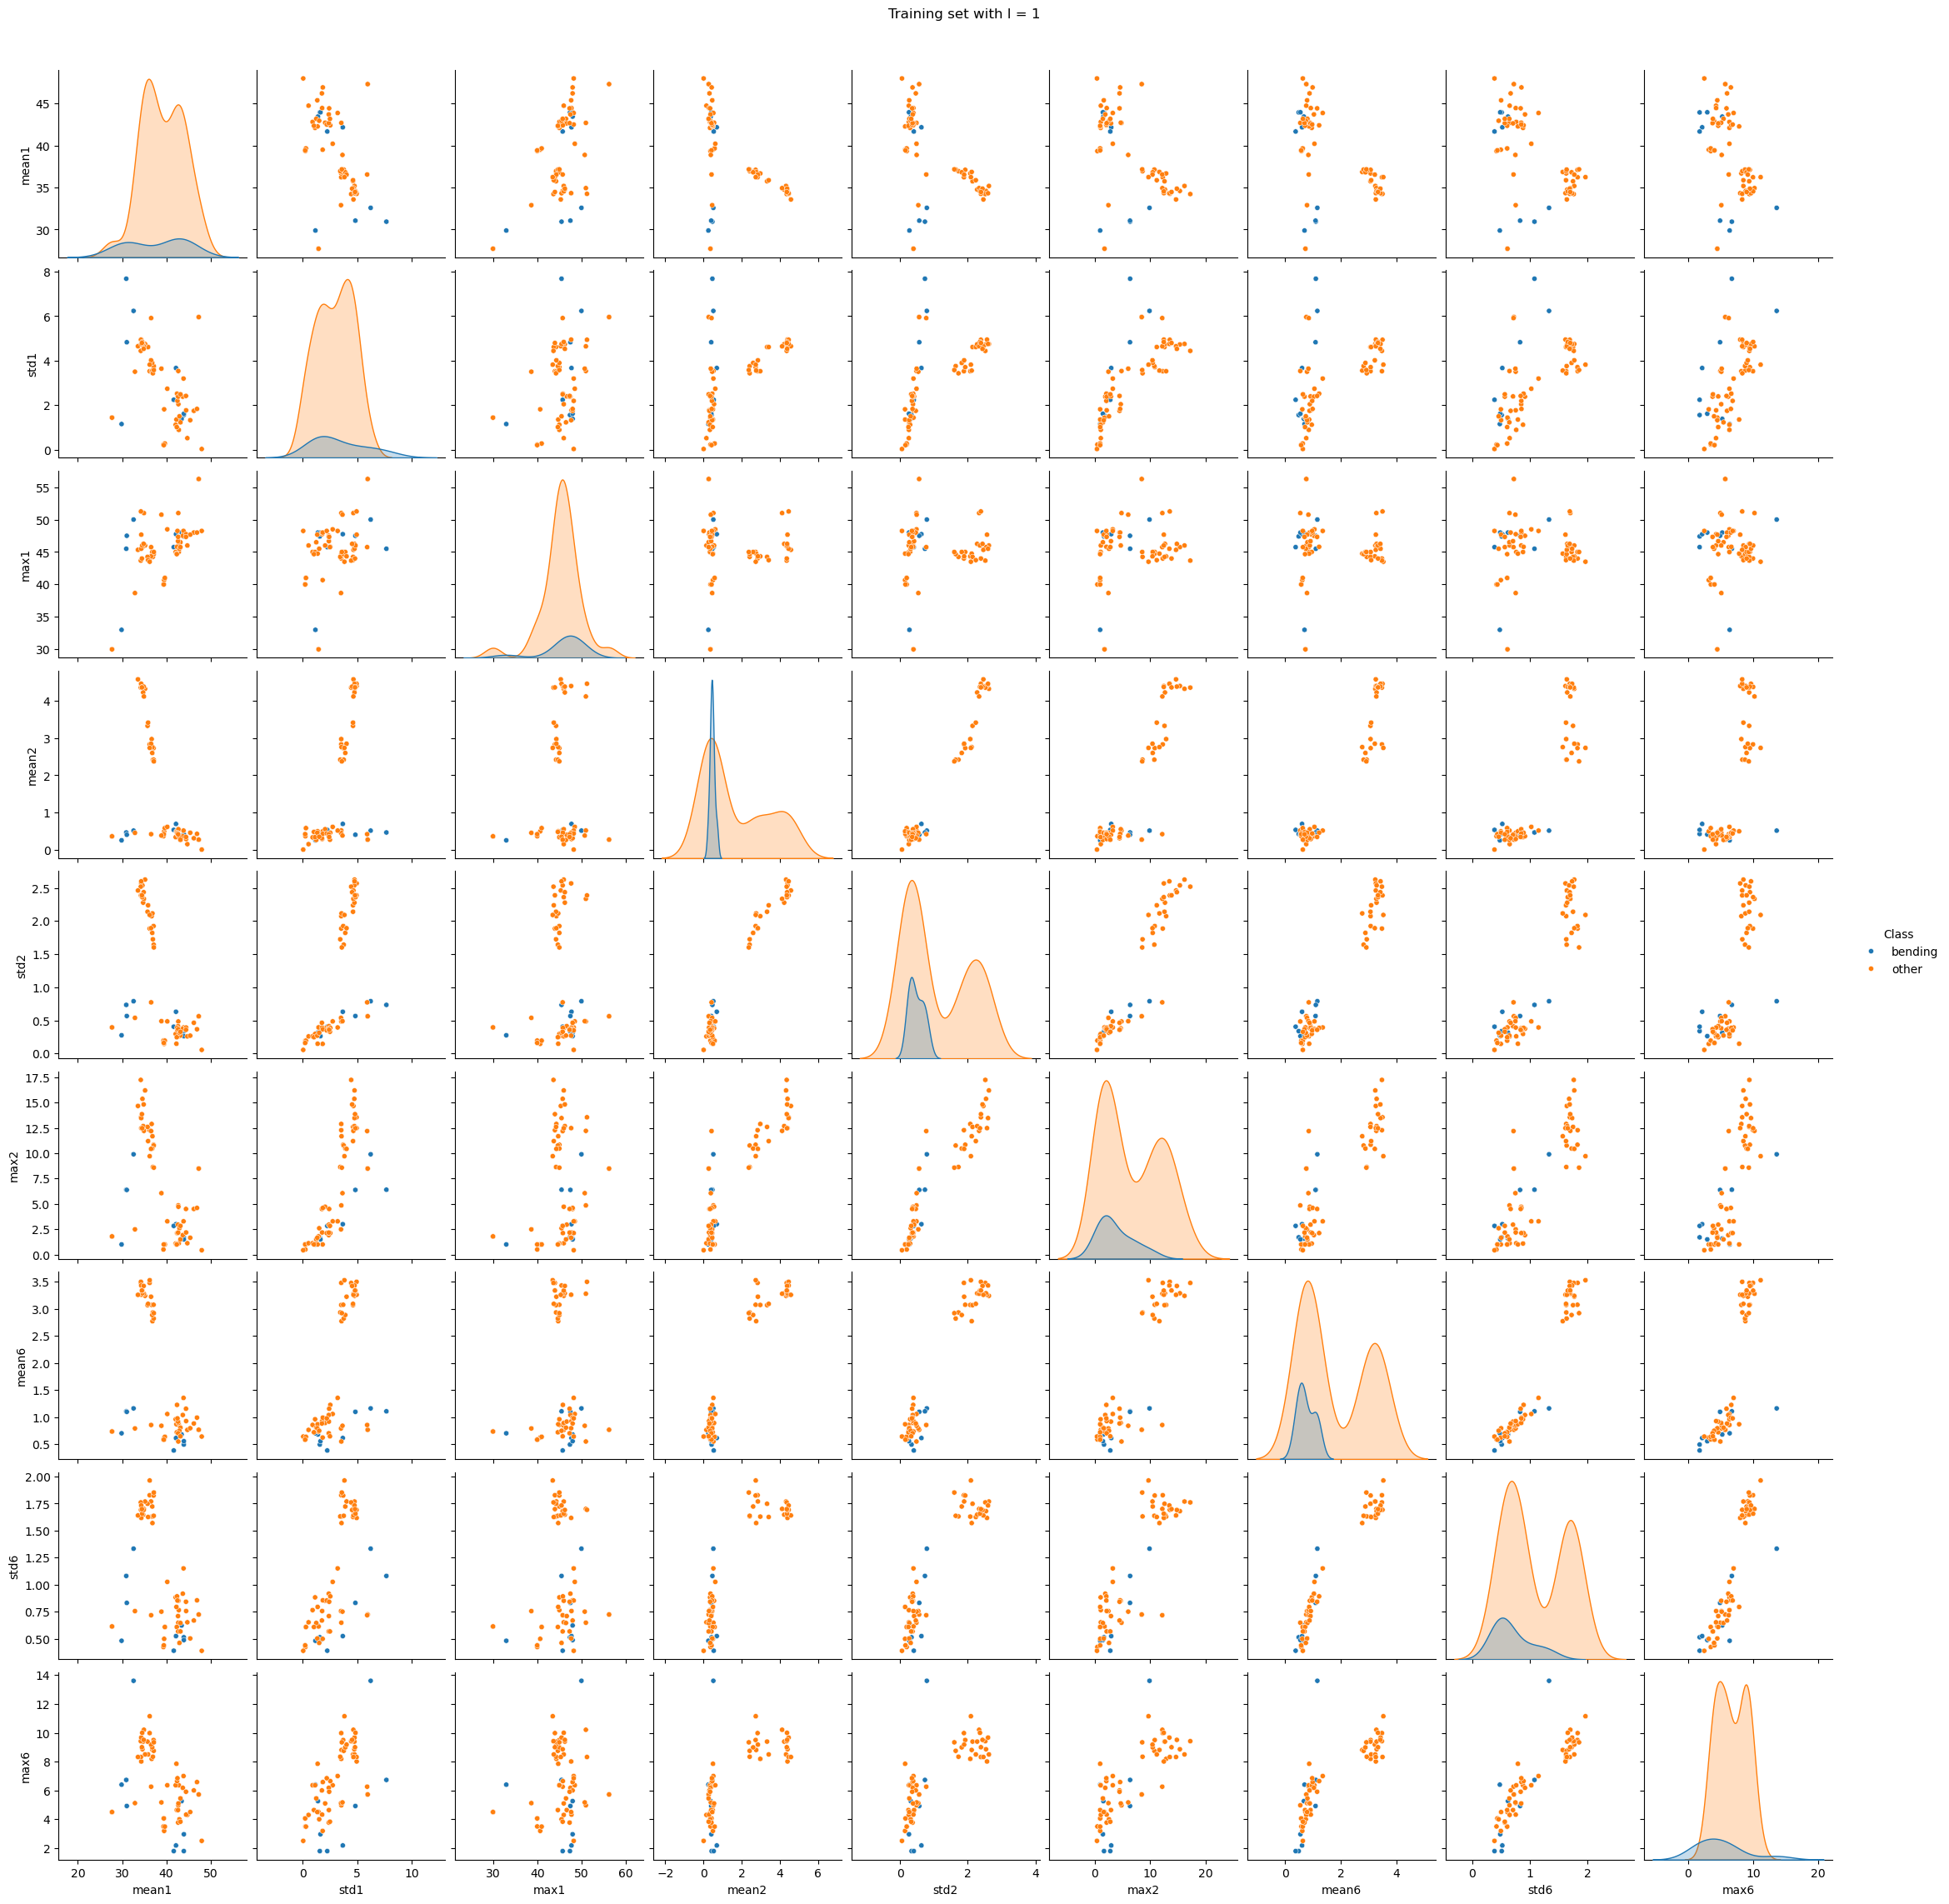

In [8]:
X_train1, y_train1 = get_data(1, "train")
cols = []
for k in (1, 2, 6):
    for stat in ("mean", "std", "max"):
        cols.append(f"{stat}{k}")

plot_df = X_train1[cols].assign(Class=np.where(y_train1 == 1, "bending", "other"))
g = sns.pairplot(plot_df, hue="Class", plot_kws={"s": 20})
g.fig.suptitle("Training set with l = 1", y=1.02)
plt.show()

#### (a) ii.

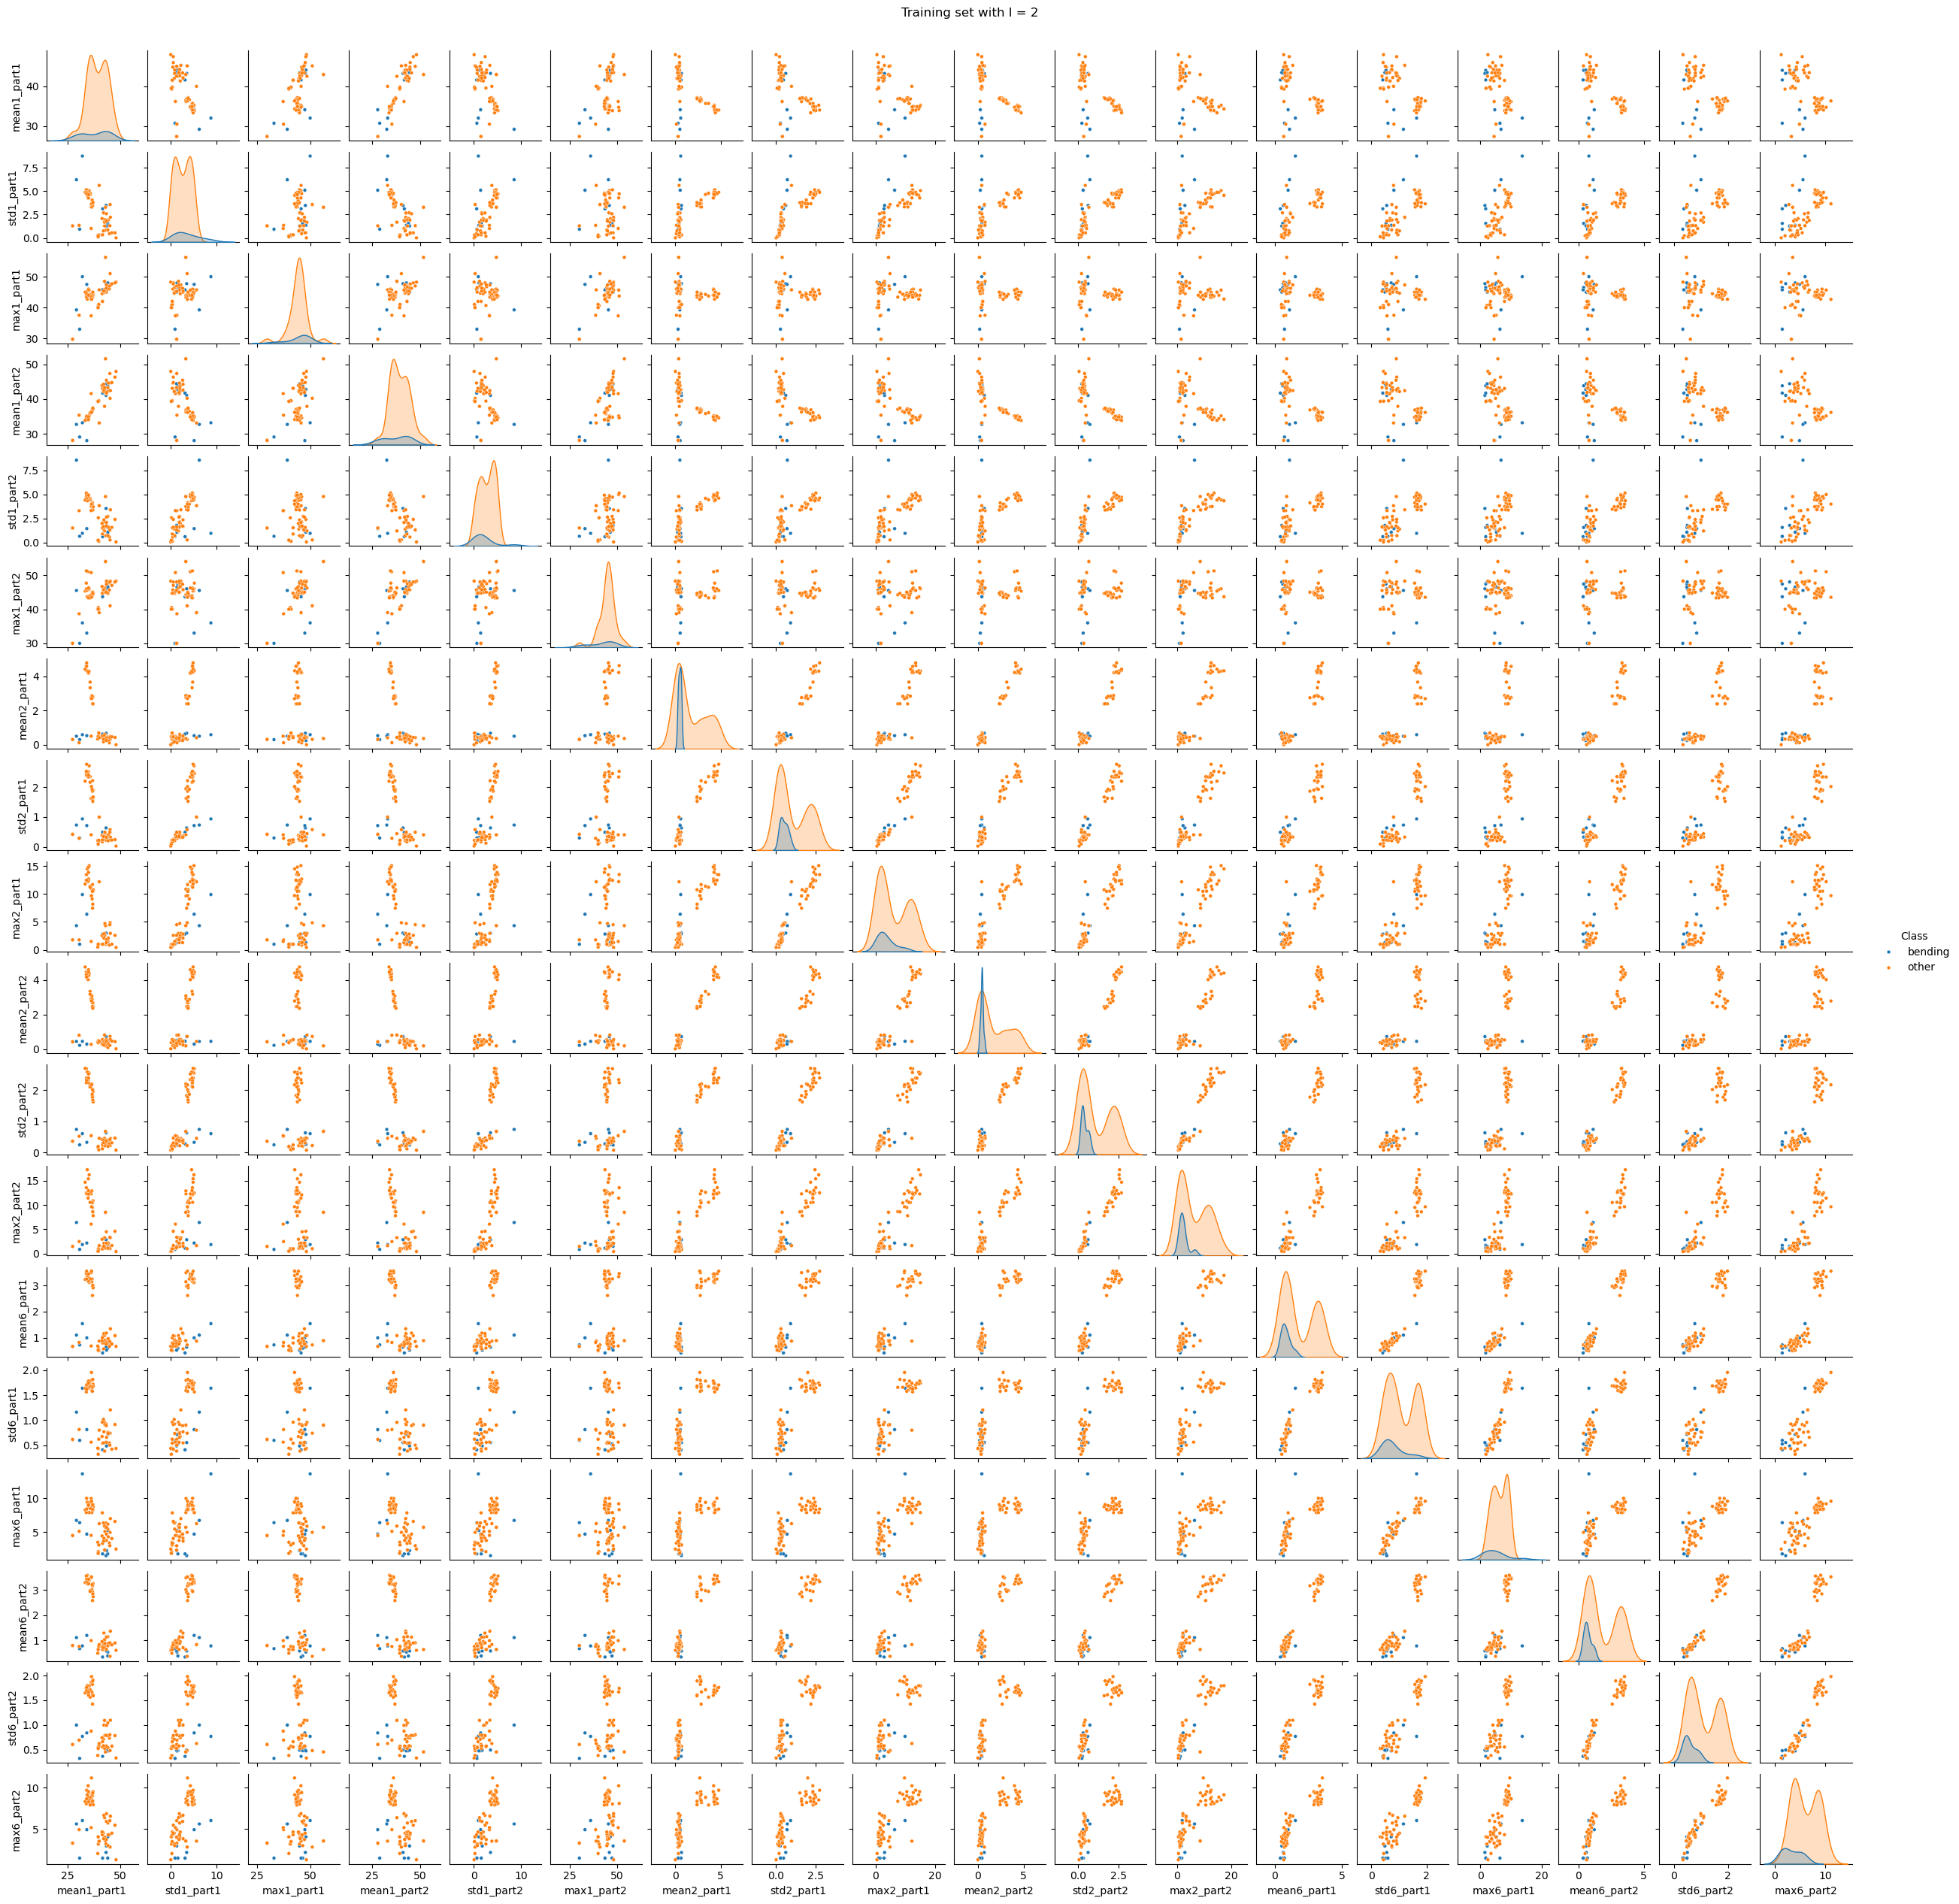

In [9]:
X_train2, y_train2 = get_data(2, "train")
cols2 = []

for k in (1, 2, 6):
    for j in (1, 2):
        for stat in ("mean", "std", "max"):
            cols2.append(f"{stat}{k}_part{j}")

plot_df2 = X_train2[cols2].assign(Class=np.where(y_train2 == 1, "bending", "other"))
g = sns.pairplot(plot_df2, hue="Class", plot_kws={"s": 12}, height=1.4)
g.fig.suptitle("Training set with l = 2", y=1.01)
plt.show()

**a ii Answer:**

No considerable difference is apparent compared with (a)(i).

#### (a) iii.

In [10]:
def rfe_cv_accuracy(X, y):
    # 5-fold CV accuracy for every p，from 1 to 15.
    X = np.asarray(X)
    acc = np.zeros(15)
    for tr, va in skf.split(X, y):
        scaler = StandardScaler().fit(X[tr])
        X_tr, X_va = scaler.transform(X[tr]), scaler.transform(X[va])
        rfe = RFE(LogisticRegression(penalty=None),n_features_to_select=1).fit(X_tr, y[tr])

        for p in range(1, 16):
            keep = rfe.ranking_ <= p
            model = LogisticRegression(penalty=None).fit(X_tr[:, keep], y[tr])
            acc[p - 1] += model.score(X_va[:, keep], y[va]) / skf.get_n_splits()
            
    return acc


rfe_acc = []
for l in range(1, 21):
    X, y = get_data(l, "train")
    rfe_acc.append(rfe_cv_accuracy(X, y))

cv_rfe = pd.DataFrame(rfe_acc, index=pd.Index(range(1, 21), name="l"), columns=pd.Index(range(1, 16), name="p"))
                      
cv_rfe.round(3)

p,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
l,,,,,,,,,,,,,,,
1,0.885,0.885,0.957,0.957,0.929,0.943,0.957,0.986,0.986,0.986,0.971,0.971,0.971,0.957,0.971
2,0.899,0.942,0.957,0.957,0.943,0.957,0.971,0.957,0.943,0.943,0.913,0.913,0.927,0.927,0.943
3,0.899,0.899,0.913,0.943,0.929,0.943,0.943,0.943,0.929,0.943,0.943,0.943,0.943,0.943,0.929
4,0.943,0.900,0.929,0.914,0.914,0.929,0.914,0.914,0.914,0.914,0.929,0.943,0.943,0.943,0.957
5,0.943,0.913,0.913,0.943,0.929,0.927,0.927,0.942,0.942,0.942,0.956,0.956,0.942,0.899,0.899
6,0.957,0.927,0.929,0.929,0.943,0.943,0.943,0.929,0.929,0.929,0.943,0.943,0.957,0.957,0.943
7,0.899,0.913,0.913,0.913,0.927,0.942,0.943,0.942,0.942,0.942,0.942,0.913,0.913,0.885,0.885
8,0.913,0.914,0.914,0.899,0.913,0.914,0.900,0.886,0.929,0.929,0.929,0.914,0.929,0.943,0.943
9,0.929,0.914,0.913,0.942,0.942,0.942,0.912,0.912,0.913,0.913,0.913,0.913,0.929,0.929,0.929


In [11]:
best_l, best_p = cv_rfe.stack().idxmax()  
print(f"Best (l, p) = ({best_l}, {best_p}),  CV accuracy = {cv_rfe.loc[best_l, best_p]:.4f}")

Best (l, p) = (1, 8),  CV accuracy = 0.9857


**a iii Answer:**

- The Wrong way to perform cross-validation is to select the features using the whole training set first, and then use cross-validation only to evaluate the model with the selected features. The feature selection has already used the information from validation folds, so the CV accuracy may be too optimistic. The right way is to select features using only the training folds each time, and  test the model on the held-out fold.
- The best pair is (l, p) = (1, 8) with CV accuracy 0.9857.

#### (a) iv.

In [12]:
X_tr, y_tr = get_data(best_l, "train")
X_te, y_te = get_data(best_l, "test")

scaler = StandardScaler().fit(X_tr)
Z_tr = pd.DataFrame(scaler.transform(X_tr), columns=X_tr.columns)
Z_te = pd.DataFrame(scaler.transform(X_te), columns=X_te.columns)

rfe = RFE(LogisticRegression(penalty=None),n_features_to_select=best_p).fit(Z_tr, y_tr)
selected = list(Z_tr.columns[rfe.support_])
final_lr = LogisticRegression(penalty=None).fit(Z_tr[selected], y_tr)
print("Selected features:", selected)

Selected features: ['3rd_quart1', '3rd_quart3', 'max4', '1st_quart4', 'min5', 'max5', 'mean5', '1st_quart6']


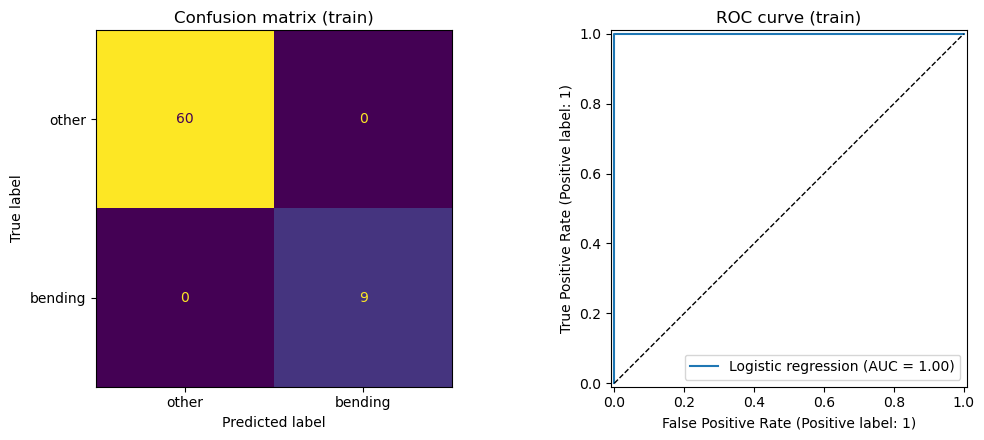

AUC (train) = 1.0000


In [13]:
def show_binary_results(model, X, y, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    ConfusionMatrixDisplay.from_predictions(y, model.predict(X), display_labels=["other", "bending"],
                                            ax=axes[0], colorbar=False)
    axes[0].set_title(f"Confusion matrix ({title})")
    RocCurveDisplay.from_estimator(model, X, y, ax=axes[1],name="Logistic regression")
    axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[1].set_title(f"ROC curve ({title})")
    plt.tight_layout()
    plt.show()
    print(f"AUC ({title}) = {roc_auc_score(y, model.predict_proba(X)[:, 1]):.4f}")


show_binary_results(final_lr, Z_tr[selected], y_tr, "train")

In [14]:
def logit_pvalues(model, X):
    X1 = np.column_stack([np.ones(len(X)), X])
    prob = model.predict_proba(X)[:, 1]
    cov = np.linalg.inv(X1.T @ (X1 * (prob * (1 - prob))[:, None]))
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    se = np.sqrt(np.diag(cov))
    return pd.DataFrame({"beta": beta, "std. error": se, "p-value": 2 * stats.norm.sf(np.abs(beta / se))},
                        index=["intercept"] + list(X.columns))


logit_pvalues(final_lr, Z_tr[selected])

,beta,std. error,p-value
intercept,-12.137336,24.019265,0.613336
3rd_quart1,-3.677558,19.671100,0.851698
3rd_quart3,-2.018473,19.235983,0.916430
max4,2.909964,28.725169,0.919309
1st_quart4,-3.118972,59.338391,0.958081
min5,4.621017,42.491441,0.913399
max5,5.063211,27.530632,0.854083
mean5,3.184319,60.421874,0.957970
1st_quart6,-3.133755,59.117160,0.957725


#### (a) v.

In [15]:
test_acc = accuracy_score(y_te, final_lr.predict(Z_te[selected]))
pd.DataFrame({"Accuracy": [cv_rfe.loc[best_l, best_p], test_acc]},
             index=["5-fold CV (train)", "Test set"]).round(4)

,Accuracy
5-fold CV (train),0.9857
Test set,1.0000


**a v Answer:**

The test accuracy is 1.0000 and the CV accuracy is 0.9857. The test accuracy is slightly higher, and the two are very close.

#### (a) vi.

**a vi Answer:**

Yes. The classes are well-separated. The model classifies all training instances correctly and the AUC is 1. This causes instability in the parameters, the standard errors of the coefficients are very large about 19 to 60 and all p-values are larger than 0.6. Therefore, no coefficient looks significant even though the model separates two classes perfectly.

#### (a) vii.

In [16]:
#all bending cases and the same number of randomly chosen controls
rng = np.random.default_rng(SEED)
cases = np.flatnonzero(y_tr == 1)
controls = rng.choice(np.flatnonzero(y_tr == 0),size=len(cases), replace=False)
cc_idx = np.r_[cases, controls]

cc_lr = LogisticRegression(penalty=None).fit(Z_tr[selected].iloc[cc_idx], y_tr[cc_idx])

# Adjust intercept 
pi = y_tr.mean()
pi_sample = y_tr[cc_idx].mean()
cc_lr.intercept_ += np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
print(f"pi = {pi:.4f},  pi_sample = {pi_sample:.4f}")

pi = 0.1304,  pi_sample = 0.5000


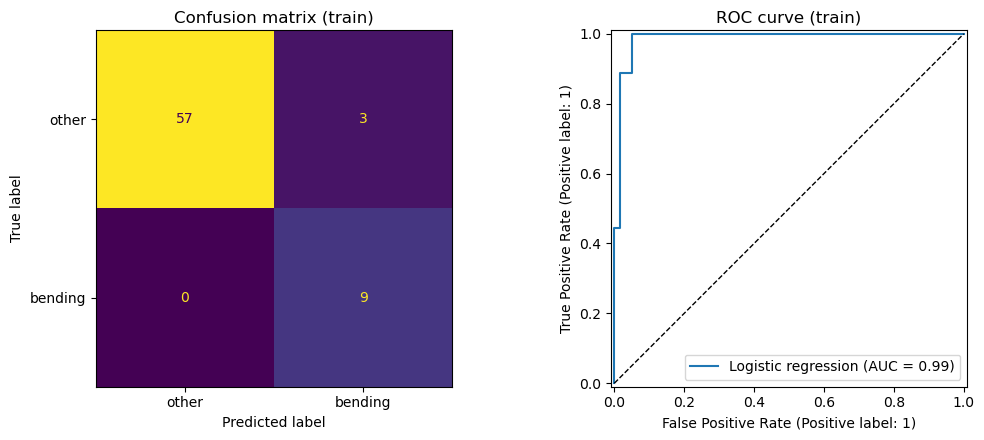

AUC (train) = 0.9870


In [17]:
show_binary_results(cc_lr, Z_tr[selected], y_tr, "train")

**a vii Answer:**

Yes. The confusion matrix in (a) iv shows 60 other instances but only 9 bending instances in the training set, so the classes are imbalanced. The case-control model misclassifies 3 of the 69 training instances, and its AUC is 0.9870.

### (b) Binary Classification Using L1-penalized Logistic Regression
#### (b) i.

In [18]:
Cs = np.logspace(-2, 3, 11)

l1_search = {}
best_C = []
cv_acc = []
for l in range(1, 21):
    X, y = get_data(l, "train")
    pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", random_state=SEED))
    l1_search[l] = GridSearchCV(pipe, {"logisticregression__C": Cs}, cv=skf).fit(X, y)
    best_C.append(l1_search[l].best_params_["logisticregression__C"])
    cv_acc.append(l1_search[l].best_score_)

cv_l1 = pd.DataFrame({"best C": best_C, "CV accuracy": cv_acc}, index=pd.Index(range(1, 21), name="l"))
cv_l1.round(4)

,best C,CV accuracy
l,,
1,1.0000,0.9571
2,1.0000,0.9571
3,0.3162,0.9714
4,1.0000,0.9571
5,3.1623,0.9418
6,3.1623,0.9571
7,0.3162,0.9275
8,1.0000,0.9286
9,0.3162,0.9275


In [19]:
best_l1 = cv_l1["CV accuracy"].idxmax()    
l1_model = l1_search[best_l1].best_estimator_

X_te1, y_te1 = get_data(best_l1, "test")
l1_test_acc = accuracy_score(y_te1, l1_model.predict(X_te1))
n_nonzero = np.count_nonzero(l1_model[-1].coef_)
print(f"Best l = {best_l1},  C = {cv_l1.loc[best_l1, 'best C']:.4g},  "
      f"CV accuracy = {cv_l1.loc[best_l1,'CV accuracy']:.4f}")
print(f"Non-zero coefficients: {n_nonzero} of {X_te1.shape[1]}")
print(f"Test accuracy = {l1_test_acc:.4f}")

Best l = 19,  C = 1,  CV accuracy = 0.9857
Non-zero coefficients: 10 of 798
Test accuracy = 0.9474


#### (b) ii.

In [20]:
pd.DataFrame({
    "l": [best_l, best_l1],
    "Number of features": [best_p, n_nonzero],
    "CV accuracy": [cv_rfe.loc[best_l, best_p], cv_l1.loc[best_l1,"CV accuracy"]],
    "Test accuracy": [test_acc, l1_test_acc],
}, index=["RFE (backward selection)", "L1-penalized"]).round(4)

,l,Number of features,CV accuracy,Test accuracy
RFE (backward selection),1,8,0.9857,1.0000
L1-penalized,19,10,0.9857,0.9474


**b ii Answer:**

 Variable selection performs slightly better. Both methods have the same CV accuracy (0.9857). On the test set, variable selection with RFE has accuracy 1.0000 and the L1-penalized model has 0.9474. L1-penalized logistic regression is easier to implement. The penalty selects the features when the model is fitted, so we only need to tune C. However, Variable selection needs a separate selection step inside every CV fold.

### (c) Multi-class Classification (The Realistic Case)
#### (c) i.

In [21]:
Cs_multi = np.logspace(-1, 3, 9)

multi_search = {}
best_C = []
cv_acc = []
for l in range(1, 21):
    X, y = get_data(l, "train", multiclass=True)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="saga", max_iter=5000,
                                                              random_state=SEED))
    multi_search[l] = GridSearchCV(pipe, {"logisticregression__C": Cs_multi}, cv=skf, n_jobs=-1).fit(X, y)
    best_C.append(multi_search[l].best_params_["logisticregression__C"])
    cv_acc.append(multi_search[l].best_score_)

cv_multi = pd.DataFrame({"best C": best_C, "CV accuracy": cv_acc}, index=pd.Index(range(1, 21), name="l"))
cv_multi.round(4)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linea

,best C,CV accuracy
l,,
1,1.0000,0.9000
2,31.6228,0.8835
3,316.2278,0.8857
4,1000.0000,0.9000
5,100.0000,0.8857
6,1000.0000,0.9000
7,316.2278,0.8846
8,316.2278,0.8846
9,100.0000,0.8714


Best l = 1,  C = 1,  CV accuracy = 0.9000
Test error (L1 multinomial) = 0.1053


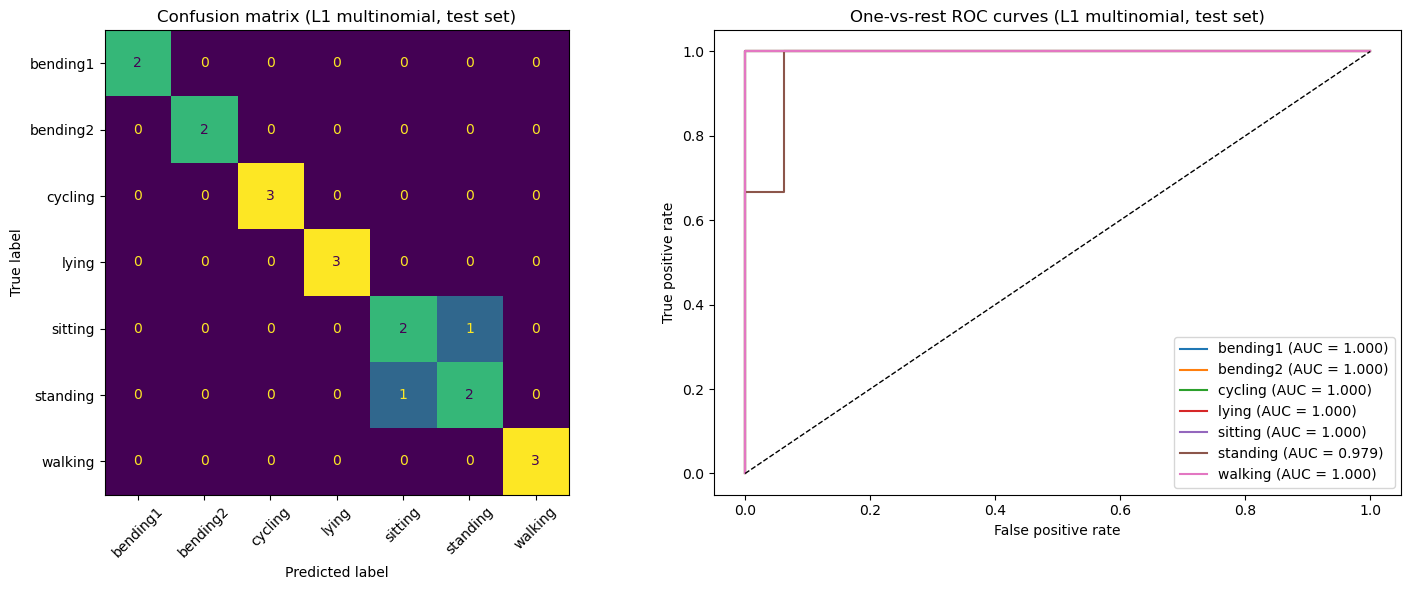

In [22]:
def show_multiclass_results(model, X, y, title):
    classes = model.classes_
    y_bin = label_binarize(y, classes=classes)
    prob = model.predict_proba(X)
    print(f"Test error ({title}) = {1 - accuracy_score(y, model.predict(X)):.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ConfusionMatrixDisplay.from_predictions(y, model.predict(X), ax=axes[0],
                                            colorbar=False, xticks_rotation=45)
    axes[0].set_title(f"Confusion matrix ({title}, test set)")

    # One-vs-rest ROC curve for each class
    for i, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_bin[:, i], prob[:, i])
        axes[1].plot(fpr, tpr, label=f"{c} (AUC = {roc_auc_score(y_bin[:, i], prob[:, i]):.3f})")
    axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[1].set_xlabel("False positive rate")
    axes[1].set_ylabel("True positive rate")
    axes[1].set_title(f"One-vs-rest ROC curves ({title}, test set)")
    axes[1].legend(loc="lower right")
    plt.tight_layout()
    plt.show()


best_lm = cv_multi["CV accuracy"].idxmax()
multi_model = multi_search[best_lm].best_estimator_
print(f"Best l = {best_lm},  C = {cv_multi.loc[best_lm, 'best C']:.4g},  "
      f"CV accuracy = {cv_multi.loc[best_lm, 'CV accuracy']:.4f}")

X_tem, y_tem = get_data(best_lm, "test", multiclass=True)
show_multiclass_results(multi_model, X_tem, y_tem, "L1 multinomial")

#### (c) ii.

In [23]:
nb_models = {"Gaussian NB": GaussianNB, "Multinomial NB": MultinomialNB}

cv_nb = pd.DataFrame(index=pd.Index(range(1, 21), name="l"))
for name, nb in nb_models.items():
    scores = []
    for l in range(1, 21):
        X, y = get_data(l, "train", multiclass=True)
        scores.append(cross_val_score(nb(), X, y, cv=skf).mean())
    cv_nb[name] = scores
cv_nb.round(4)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python

,Gaussian NB,Multinomial NB
l,,
1,0.8571,0.8714
2,0.8275,0.7703
3,0.6978,0.8132
4,0.6967,0.8275
5,0.6374,0.8275
6,0.6516,0.8132
7,0.5956,0.7989
8,0.6385,0.7703
9,0.5648,0.7989


Gaussian NB: best l = 1,  CV accuracy = 0.8571
Test error (Gaussian NB) = 0.1053


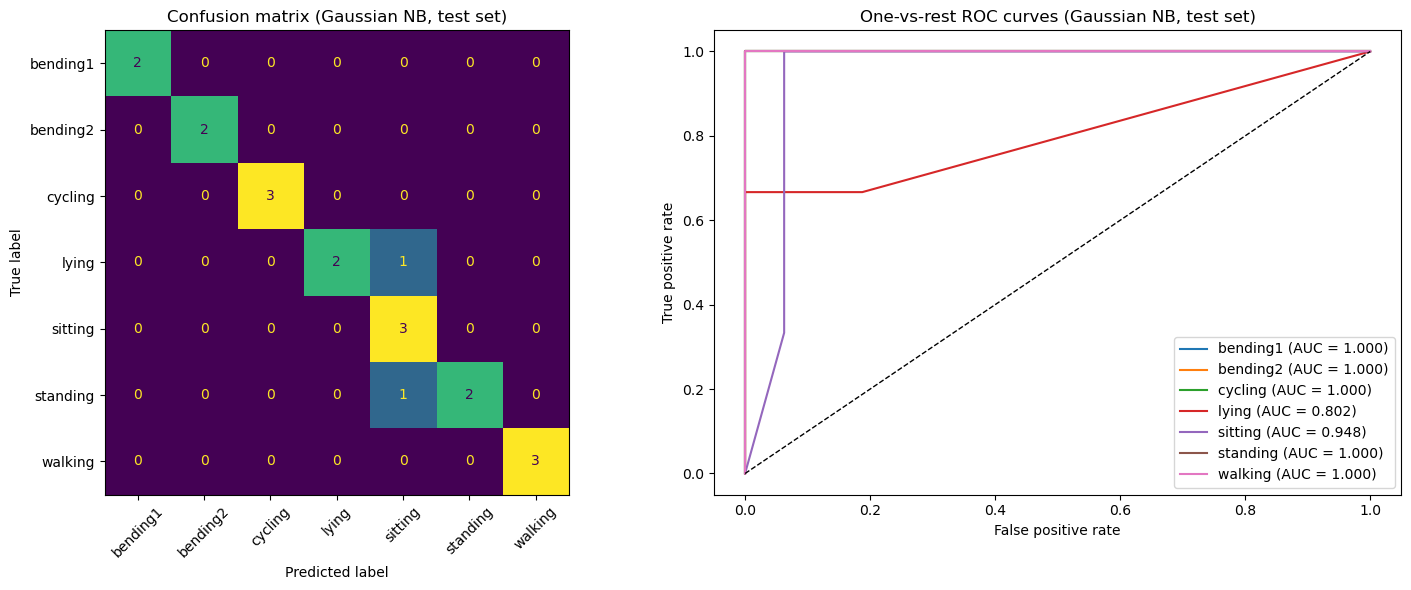

Multinomial NB: best l = 1,  CV accuracy = 0.8714
Test error (Multinomial NB) = 0.1053


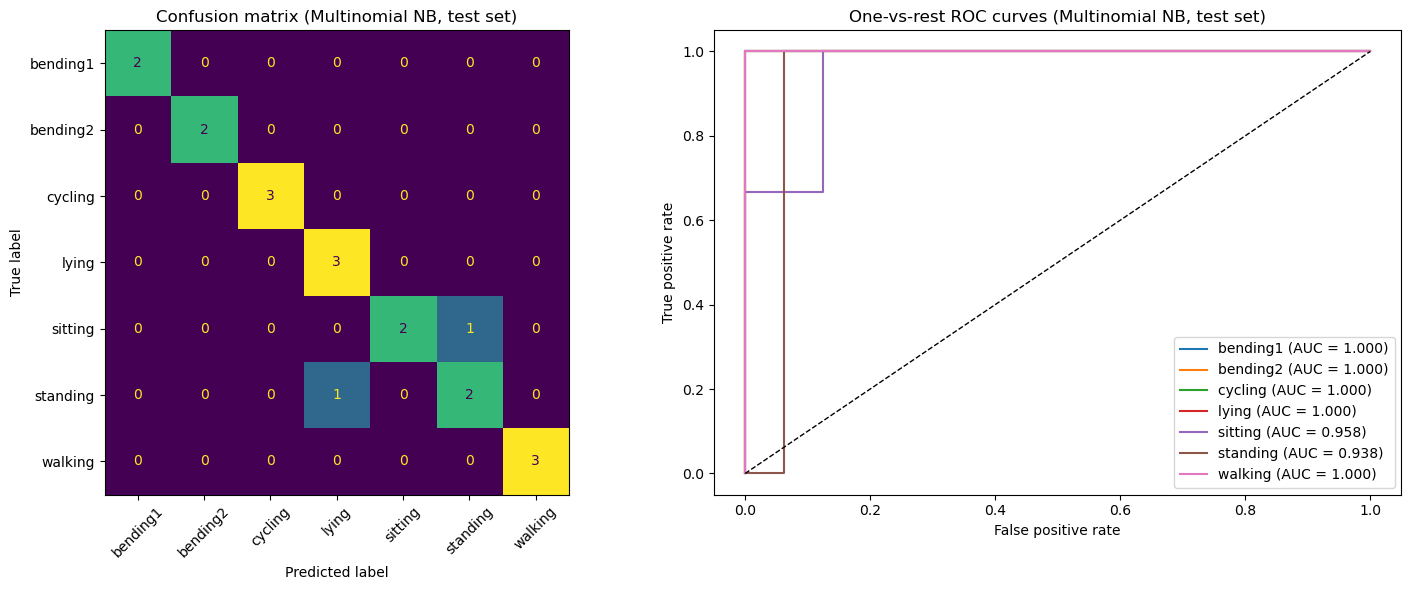

In [24]:
nb_results = {}
for name, nb in nb_models.items():
    l = cv_nb[name].idxmax()
    X, y = get_data(l, "train", multiclass=True)
    X_test, y_test = get_data(l, "test", multiclass=True)
    model = nb().fit(X, y)
    nb_results[name] = (l, cv_nb.loc[l, name], 1 - accuracy_score(y_test, model.predict(X_test)))
    print(f"{name}: best l = {l},  CV accuracy = {cv_nb.loc[l, name]:.4f}")
    show_multiclass_results(model, X_test, y_test, name)

**c ii Answer:**

Gaussian NB (l = 1) and Multinomial NB (l = 1) have the same test error, 0.1053. Multinomial NB has a slightly higher CV accuracy (0.8714 vs 0.8571), so the two perform about the same. Besides, Multinomial NB is slightly better in cross-validation. Both models only make mistakes in the static activities. Gaussian NB predicts one lying and one standing instance as sitting, and Multinomial NB predicts one sitting instance as standing and one standing instance as lying.

#### (c) iii.

In [25]:
summary = pd.DataFrame(
    [(best_lm, cv_multi.loc[best_lm, "CV accuracy"],
      1 - accuracy_score(y_tem, multi_model.predict(X_tem)))] + list(nb_results.values()),
    columns=["l", "CV accuracy", "Test error"],
    index=["L1 multinomial regression", "Gaussian NB", "Multinomial NB"])
summary.round(4)

,l,CV accuracy,Test error
L1 multinomial regression,1,0.9000,0.1053
Gaussian NB,1,0.8571,0.1053
Multinomial NB,1,0.8714,0.1053


**c iii Answer:**

 L1-penalized multinomial regression is better for multi-class classification in this problem. All three methods have the same test error (0.1053), but L1-penalized multinomial regression has the highest CV accuracy 0.9000, compared with 0.8571 for Gaussian NB and 0.8714 for Multinomial NB.

## 3. ISLR 4.8.3
This problem relates to the QDA model, in which the observations
within each class are drawn from a normal distribution with a classspecific mean vector and a class specific covariance matrix. We consider the simple case where p =1; i.e. there is only one feature.
Suppose that we have K classes, and that if an observation belongs
to the kth class then X comes from a one-dimensional normal distribution, X ∼ N(µk, σ2
k). Recall that the density function for the
one-dimensional normal distribution is given in (4.16). Prove that in
this case, the Bayes classifier is not linear. Argue that it is in fact
quadratic.


Let $\pi_k$ represent $P(Y = k)$. By Bayes theorem,

$$P(Y = k \mid X = x) = \frac{\pi_k f_k(x)}{\sum_{j=1}^{K} \pi_j f_j(x)}.$$

Since the denominator is the same for all classes, the Bayes classifier chooses the class that maximizes $\pi_k f_k(x)$, or equivalently, $\log(\pi_k f_k(x))$. The density of class $k$ is

$$f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

Take the log, and remove $-\frac{1}{2}\log(2\pi)$, which is the same for every class.

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k.$$

Because the variances are class-specific, the coefficient of $x^2$ generally differs across classes. Therefore, the Bayes classification rule is generally quadratic rather than linear. 

## 4. ISLR 4.8.7
Suppose that we wish to predict whether a given stock will issue a
dividend this year (“Yes” or “No”) based on X, last year’s percent
profit. We examine a large number of companies and discover that the
mean value of X for companies that issued a dividend was X¯ = 10,
while the mean for those that didn’t was X¯ =0. In addition, the
variance of X for these two sets of companies was σˆ2 = 36. Finally,
80 % of companies issued dividends. Assuming that X follows a normal distribution, predict the probability that a company will issue
a dividend this year given that its percentage profit was X =4 last
year.


Let $Y = 1$ represents that a company issues a dividend and $Y = 0$ otherwise. The prior probabilities are $P(Y = 1) = 0.8, P(Y = 0) = 0.2$.

The class-conditional distributions are $X \mid Y = 1 \sim N(10, 36), X \mid Y = 0 \sim N(0, 36)$.

By Bayes' theorem,

$$P(Y = 1 \mid X = 4) = \frac{0.8 f_1(4)}{0.8 f_1(4) + 0.2 f_0(4)}.$$

Use the normal densities and cancel the common factor gives

$$P(Y = 1 \mid X = 4) = \frac{0.8 e^{-(4-10)^2/(2 \cdot 36)}}{0.8 e^{-(4-10)^2/(2 \cdot 36)} + 0.2 e^{-(4-0)^2/(2 \cdot 36)}} \approx 0.75185.$$

Therefore, the estimated probability that the company will issue a dividend this year is about **75.19%**.